# StableNet 跨数据集病状迁移实验

本 notebook 用于做初步的**跨数据集泛化/迁移实验**：

- `hemorrhage_to_tumor`：用脑出血数据的 `train/val` 训练和选模，最后在脑肿瘤数据的 `test` 上判断“无病状/有病状”。
- `tumor_to_hemorrhage`：用脑肿瘤数据的 `train/val` 训练和选模，最后在脑出血数据的 `test` 上判断“无病状/有病状”。

这里不使用目标数据微调，因此更准确地说是 **zero-shot 跨数据集泛化**。阳性统一解释为“当前目标数据集中的病状阳性”，不能据此声称模型学习到了所有疾病的通用医学特征。

模型保存策略：每个训练进程只覆盖一个 `model_best.pth.tar`；每种方法依次运行 5 个随机种子，运行结束后立刻淘汰非最佳模型。整个实验最终只保留两个模型：普通 ResNet18 的最佳模型和 StableNet 的最佳模型。

## 第一阶段：实验方向与输入/输出目录

本阶段只设置路径并打印数据流。默认运行“脑出血 → 脑肿瘤”；如需反向实验，只把 `DIRECTION` 改成 `tumor_to_hemorrhage`，同时修改 `RUN_NAME`，避免覆盖第一次实验。

| 类型 | 路径 | 用途 |
|---|---|---|
| 项目代码输入 | `/root/autodl-tmp/train` | 调用 StableNet 代码 |
| 脑出血数据输入 | `/root/autodl-tmp/medical_data/brain_hemorrhage` | `negative/positive` 二分类 |
| 脑肿瘤数据输入 | `/root/autodl-tmp/medical_data/brain_tumor` | `negative/positive` 二分类 |
| 实验输出 | `/root/autodl-tmp/train/results_cross_dataset_v1/<RUN_NAME>` | 指标、日志、两个最终模型 |

In [8]:
import os
import re
import sys
import time
import random
import shutil
import hashlib
import subprocess
from pathlib import Path
from types import SimpleNamespace

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from PIL import Image
from IPython.display import display
from torch.utils.data import DataLoader
from torchvision import transforms
from torchvision.datasets import ImageFolder
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, confusion_matrix,
    precision_score, recall_score, f1_score, roc_auc_score,
)

ROOT = Path("/root/autodl-tmp")
PROJECT_DIR = ROOT / "train"
MEDICAL_DATA_ROOT = ROOT / "medical_data"

# 可选："hemorrhage_to_tumor" 或 "tumor_to_hemorrhage"
DIRECTION = "tumor_to_hemorrhage"
RUN_NAME = "tumor_to_hemorrhage_v1"

DIRECTION_CONFIG = {
    "hemorrhage_to_tumor": {
        "source_name": "BrainHemorrhage",
        "source_dir": MEDICAL_DATA_ROOT / "brain_hemorrhage",
        "target_name": "BrainTumor",
        "target_dir": MEDICAL_DATA_ROOT / "brain_tumor",
        "dataset_name": "CrossDisease_H2T",
    },
    "tumor_to_hemorrhage": {
        "source_name": "BrainTumor",
        "source_dir": MEDICAL_DATA_ROOT / "brain_tumor",
        "target_name": "BrainHemorrhage",
        "target_dir": MEDICAL_DATA_ROOT / "brain_hemorrhage",
        "dataset_name": "CrossDisease_T2H",
    },
}

cfg = DIRECTION_CONFIG[DIRECTION]
SOURCE_NAME = cfg["source_name"]
SOURCE_DATA_DIR = Path(cfg["source_dir"])
TARGET_NAME = cfg["target_name"]
TARGET_DATA_DIR = Path(cfg["target_dir"])
DATASET_NAME = cfg["dataset_name"]
RUN_ROOT = PROJECT_DIR / "results_cross_dataset_v1" / RUN_NAME

NUM_CLASSES = 2
EPOCHS = 30
BATCH_SIZE = 16
N_FEATURE = BATCH_SIZE
GPU = 0
SEEDS = [1, 3, 7, 21, 42]

LR = 0.01
WEIGHT_DECAY = 0.0001
LRBL = 1.0
LAMBDAP = 70.0
EPOCHB = 20

METHODS = {
    "ResNet18_ERM": EPOCHS + 1,  # StableNet 关闭
    "StableNet": 0,              # 第一个 epoch 开启
}

os.chdir(PROJECT_DIR)

print("=" * 76)
print("跨数据集病状迁移实验：输入与输出")
print("=" * 76)
print(f"训练输入（源数据） : {SOURCE_DATA_DIR}")
print(f"  使用目录         : {SOURCE_DATA_DIR / 'train'}")
print(f"  选模目录         : {SOURCE_DATA_DIR / 'val'}")
print(f"最终测试（目标）   : {TARGET_DATA_DIR / 'test'}")
print(f"实验输出根目录     : {RUN_ROOT}")
print(f"最终模型输出       : {RUN_ROOT / '<method>' / 'best_model.pth.tar'}")
print(f"全部指标输出       : {RUN_ROOT / 'all_runs.csv'}")
print(f"汇总指标输出       : {RUN_ROOT / 'summary.csv'}")
print("类别语义           : negative=无病状，positive=有病状")
print("注意               : 目标数据 test 不参与训练、epoch 选择或 seed 选择")
print("=" * 76)

跨数据集病状迁移实验：输入与输出
训练输入（源数据） : /root/autodl-tmp/medical_data/brain_tumor
  使用目录         : /root/autodl-tmp/medical_data/brain_tumor/train
  选模目录         : /root/autodl-tmp/medical_data/brain_tumor/val
最终测试（目标）   : /root/autodl-tmp/medical_data/brain_hemorrhage/test
实验输出根目录     : /root/autodl-tmp/train/results_cross_dataset_v1/tumor_to_hemorrhage_v1
最终模型输出       : /root/autodl-tmp/train/results_cross_dataset_v1/tumor_to_hemorrhage_v1/<method>/best_model.pth.tar
全部指标输出       : /root/autodl-tmp/train/results_cross_dataset_v1/tumor_to_hemorrhage_v1/all_runs.csv
汇总指标输出       : /root/autodl-tmp/train/results_cross_dataset_v1/tumor_to_hemorrhage_v1/summary.csv
类别语义           : negative=无病状，positive=有病状
注意               : 目标数据 test 不参与训练、epoch 选择或 seed 选择


## 第二阶段：训练前检查

检查源数据和目标数据是否都具有 `train/val/test/negative/positive` 结构，确认类别顺序一致，并阻止旧实验结果与本次实验混合。这里不创建或复制医学图片。

In [9]:
IMAGE_SUFFIXES = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}
EXPECTED_CLASSES = {"negative": 0, "positive": 1}

def image_files(folder):
    return sorted(
        path for path in Path(folder).glob("*")
        if path.is_file() and path.suffix.lower() in IMAGE_SUFFIXES
    )

def inspect_dataset(name, root):
    rows = []
    for split in ("train", "val", "test"):
        split_dataset = ImageFolder(Path(root) / split)
        if split_dataset.class_to_idx != EXPECTED_CLASSES:
            raise ValueError(
                f"{name}/{split} 类别映射错误：{split_dataset.class_to_idx}"
            )
        for class_name in EXPECTED_CLASSES:
            folder = Path(root) / split / class_name
            files = image_files(folder)
            if not files:
                raise FileNotFoundError(f"目录为空：{folder}")
            rows.append({
                "dataset": name,
                "split": split,
                "class": class_name,
                "count": len(files),
                "input_path": str(folder),
            })
    return rows

if not (PROJECT_DIR / "main_stablenet.py").is_file():
    raise FileNotFoundError(PROJECT_DIR / "main_stablenet.py")

layout_df = pd.DataFrame(
    inspect_dataset(SOURCE_NAME, SOURCE_DATA_DIR)
    + inspect_dataset(TARGET_NAME, TARGET_DATA_DIR)
)
display(layout_df)

# 精确重复图片检查：防止源训练/验证图片直接出现在目标测试集。
# 该检查能发现字节完全相同的文件，但不能代替患者 ID 级划分检查。
CHECK_EXACT_DUPLICATES = True
if CHECK_EXACT_DUPLICATES:
    groups = {
        "source_train": [
            path for class_name in EXPECTED_CLASSES
            for path in image_files(SOURCE_DATA_DIR / "train" / class_name)
        ],
        "source_val": [
            path for class_name in EXPECTED_CLASSES
            for path in image_files(SOURCE_DATA_DIR / "val" / class_name)
        ],
        "target_test": [
            path for class_name in EXPECTED_CLASSES
            for path in image_files(TARGET_DATA_DIR / "test" / class_name)
        ],
    }
    seen = {}
    duplicates = []
    for group_name, files in groups.items():
        for path in files:
            digest = hashlib.sha256(path.read_bytes()).hexdigest()
            if digest in seen and seen[digest][0] != group_name:
                duplicates.append((seen[digest][1], path))
            else:
                seen[digest] = (group_name, path)
    if duplicates:
        sample = "\n".join(f"{left}  <=>  {right}" for left, right in duplicates[:10])
        raise RuntimeError(
            f"发现 {len(duplicates)} 组跨划分完全重复图片，实验已停止。\n{sample}"
        )
    print("精确重复图片检查通过。")

# 防止同名实验混入旧模型。若这里报错，请更换 RUN_NAME。
existing_models = list(RUN_ROOT.rglob("*.pth.tar")) if RUN_ROOT.exists() else []
if existing_models:
    raise RuntimeError(
        f"输出目录已有 {len(existing_models)} 个模型。请修改 RUN_NAME，"
        "不要把两次实验写入同一目录。"
    )
RUN_ROOT.mkdir(parents=True, exist_ok=True)
layout_df.to_csv(RUN_ROOT / "data_layout.csv", index=False)
print("训练前检查通过。数据结构记录：", RUN_ROOT / "data_layout.csv")

,dataset,split,class,count,input_path
0,BrainTumor,train,negative,1050,/root/autodl-tmp/medical_data/brain_tumor/trai...
1,BrainTumor,train,positive,1050,/root/autodl-tmp/medical_data/brain_tumor/trai...
2,BrainTumor,val,negative,225,/root/autodl-tmp/medical_data/brain_tumor/val/...
3,BrainTumor,val,positive,225,/root/autodl-tmp/medical_data/brain_tumor/val/...
4,BrainTumor,test,negative,225,/root/autodl-tmp/medical_data/brain_tumor/test...
5,BrainTumor,test,positive,225,/root/autodl-tmp/medical_data/brain_tumor/test...
6,BrainHemorrhage,train,negative,70,/root/autodl-tmp/medical_data/brain_hemorrhage...
7,BrainHemorrhage,train,positive,70,/root/autodl-tmp/medical_data/brain_hemorrhage...
8,BrainHemorrhage,val,negative,15,/root/autodl-tmp/medical_data/brain_hemorrhage...
9,BrainHemorrhage,val,positive,15,/root/autodl-tmp/medical_data/brain_hemorrhage...


精确重复图片检查通过。


RuntimeError: 输出目录已有 2 个模型。请修改 RUN_NAME，不要把两次实验写入同一目录。

In [10]:
# 检查 main_stablenet.py 与 saving.py 是否采用“只覆盖验证集最佳模型”的低占盘逻辑。
main_path = PROJECT_DIR / "main_stablenet.py"
saving_path = PROJECT_DIR / "utilis" / "saving.py"
main_source = main_path.read_text(encoding="utf-8")
saving_source = saving_path.read_text(encoding="utf-8")

required_main_fragments = [
    "is_best = val_acc1 > best_acc1",
    "save_checkpoint(",
]
required_saving_fragments = [
    "if not is_best:",
    '"model_best.pth.tar"',
    "torch.save(",
]
for fragment in required_main_fragments:
    if fragment not in main_source:
        raise RuntimeError(f"main_stablenet.py 缺少关键逻辑：{fragment}")
for fragment in required_saving_fragments:
    if fragment not in saving_source:
        raise RuntimeError(f"saving.py 缺少关键逻辑：{fragment}")

print("模型保存检查通过：训练过程中每次运行只覆盖一个验证集最佳 checkpoint。")

模型保存检查通过：训练过程中每次运行只覆盖一个验证集最佳 checkpoint。


## 第三阶段：辅助函数

统一目标数据预处理、checkpoint 加载和评价指标。模型必须完整加载；若结构或权重不一致会立即报错，而不是静默生成不可靠结果。

In [11]:
test_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225],
    ),
])

def remove_module_prefix(state_dict):
    return {key.removeprefix("module."): value for key, value in state_dict.items()}

def load_checkpoint_model(checkpoint_path):
    import models

    checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=False)
    state_dict = remove_module_prefix(checkpoint["state_dict"])
    if "pre_features" in state_dict:
        n_feature, feature_dim = state_dict["pre_features"].shape[:2]
    else:
        n_feature, feature_dim = N_FEATURE, 512

    model_args = SimpleNamespace(
        n_feature=int(n_feature), feature_dim=int(feature_dim), n_levels=1
    )
    model = models.resnet18_with_table(pretrained=False, args=model_args)
    model.fc1 = nn.Linear(model.fc1.in_features, NUM_CLASSES)
    model.load_state_dict(state_dict, strict=True)
    device = torch.device(f"cuda:{GPU}" if torch.cuda.is_available() else "cpu")
    return model.to(device).eval(), checkpoint, device

def parse_epoch_results(raw_output):
    matches = re.findall(
        r"\*\s+Acc@1\s+([-\d.]+)\s+Acc@(?:2|5)\s+([-\d.]+)",
        raw_output,
    )
    rows = []
    for index in range(0, len(matches), 2):
        if index + 1 >= len(matches):
            break
        rows.append({
            "epoch": index // 2 + 1,
            "source_val_accuracy": float(matches[index][0]),
            "source_test_accuracy_during_training": float(matches[index + 1][0]),
        })
    return rows

@torch.no_grad()
def evaluate_on_target(checkpoint_path, method_name, seed):
    model, checkpoint, device = load_checkpoint_model(checkpoint_path)
    dataset = ImageFolder(TARGET_DATA_DIR / "test", transform=test_transform)
    if dataset.class_to_idx != EXPECTED_CLASSES:
        raise ValueError(f"目标测试类别映射错误：{dataset.class_to_idx}")
    loader = DataLoader(
        dataset, batch_size=BATCH_SIZE, shuffle=False,
        num_workers=4, pin_memory=True,
    )

    y_true, y_pred, y_prob, image_paths = [], [], [], []
    offset = 0
    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        output = model(images)
        logits = output[0] if isinstance(output, tuple) else output
        probabilities = torch.softmax(logits, dim=1)
        predictions = logits.argmax(dim=1)
        batch_n = labels.numel()
        image_paths.extend(path for path, _ in dataset.samples[offset:offset + batch_n])
        offset += batch_n
        y_true.extend(labels.numpy().tolist())
        y_pred.extend(predictions.cpu().numpy().tolist())
        y_prob.extend(probabilities[:, 1].cpu().numpy().tolist())

    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    y_prob = np.asarray(y_prob)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    try:
        auc = 100 * roc_auc_score(y_true, y_prob)
    except ValueError:
        auc = np.nan

    metrics = {
        "target_accuracy": 100 * accuracy_score(y_true, y_pred),
        "target_balanced_accuracy": 100 * balanced_accuracy_score(y_true, y_pred),
        "target_sensitivity": 100 * recall_score(y_true, y_pred, zero_division=0),
        "target_specificity": 100 * tn / (tn + fp) if tn + fp else np.nan,
        "target_precision": 100 * precision_score(y_true, y_pred, zero_division=0),
        "target_f1": 100 * f1_score(y_true, y_pred, zero_division=0),
        "target_roc_auc": auc,
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
    }
    predictions_df = pd.DataFrame({
        "image_path": image_paths,
        "true_index": y_true,
        "true_label": np.where(y_true == 1, "有病状", "无病状"),
        "predicted_index": y_pred,
        "predicted_label": np.where(y_pred == 1, "有病状", "无病状"),
        "probability_disease": y_prob,
        "correct": y_true == y_pred,
        "method": method_name,
        "seed": seed,
    })
    return metrics, predictions_df

def better_run(candidate, current):
    if current is None:
        return True
    return (candidate["source_best_val_accuracy"], -candidate["seed"]) > (
        current["source_best_val_accuracy"], -current["seed"]
    )

## 第四阶段：5 个随机种子训练与即时模型淘汰

每个方法运行 5 个随机种子。训练命令只接收源数据路径，因此目标数据不会进入训练过程。每次训练内部只保留源验证集最佳 epoch；该 seed 结束后立刻与当前最佳 seed 比较，较差模型马上删除。

最终选模依据只有 `source_best_val_accuracy`，目标测试结果只用于最后汇报，绝不参与模型选择。

In [12]:
records = []
best_by_method = {method_name: None for method_name in METHODS}
failed_runs = []

for method_name, epochp in METHODS.items():
    method_dir = RUN_ROOT / method_name
    method_dir.mkdir(parents=True, exist_ok=True)
    final_model_path = method_dir / "best_model.pth.tar"

    for run_index, seed in enumerate(SEEDS, start=1):
        print("\n" + "=" * 82)
        print(f"方法：{method_name} | seed {run_index}/{len(SEEDS)} = {seed}")
        print(f"训练输入：{SOURCE_DATA_DIR / 'train'}")
        print(f"选模输入：{SOURCE_DATA_DIR / 'val'}")
        print(f"最终测试：{TARGET_DATA_DIR / 'test'}（不参与选模）")
        print(f"临时输出：{method_dir / f'seed_{seed}'}")
        print(f"最终模型：{final_model_path}")
        print("=" * 82)

        seed_dir = method_dir / f"seed_{seed}"
        seed_dir.mkdir(parents=True, exist_ok=True)
        source_checkpoint = seed_dir / DATASET_NAME / "model_best.pth.tar"
        if source_checkpoint.exists():
            raise RuntimeError(
                f"发现旧的临时模型：{source_checkpoint}。请修改 RUN_NAME 后重新运行。"
            )

        cmd = [
            sys.executable, "-u", "main_stablenet.py",
            "-data", str(SOURCE_DATA_DIR),
            "--dataset", DATASET_NAME,
            "--classes_num", str(NUM_CLASSES),
            "--gpu", str(GPU),
            "--batch-size", str(BATCH_SIZE),
            "--n_feature", str(N_FEATURE),
            "--workers", "4",
            "--epochs", str(EPOCHS),
            "--epochp", str(epochp),
            "--lr", str(LR),
            "--wd", str(WEIGHT_DECAY),
            "--cos", "1",
            "--lrbl", str(LRBL),
            "--lambdap", str(LAMBDAP),
            "--epochb", str(EPOCHB),
            "--seed", str(seed),
            "--log_base", str(seed_dir),
        ]

        print("运行命令：")
        print(" ".join(cmd))
        start_time = time.time()
        process = subprocess.Popen(
            cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
            text=True, bufsize=1,
        )
        lines = []
        evaluation_index = 0
        for line in process.stdout:
            lines.append(line)
            if "* Acc@1" in line:
                epoch_number = evaluation_index // 2 + 1
                phase = "Source-Val" if evaluation_index % 2 == 0 else "Source-Test"
                print(f">>> Epoch {epoch_number:02d} {phase:11s} | {line.strip()}")
                evaluation_index += 1
        process.wait()

        raw_output = "".join(lines)
        training_log_path = seed_dir / "training_output.txt"
        training_log_path.write_text(raw_output, encoding="utf-8")
        if process.returncode != 0:
            failed_runs.append((method_name, seed))
            if source_checkpoint.exists():
                source_checkpoint.unlink()
            print("训练失败，最后 60 行：")
            print("".join(lines[-60:]))
            continue

        epoch_rows = parse_epoch_results(raw_output)
        if not epoch_rows or not source_checkpoint.is_file():
            failed_runs.append((method_name, seed))
            if source_checkpoint.exists():
                source_checkpoint.unlink()
            print("没有解析到完整结果或没有生成最佳模型。")
            continue

        best_epoch_row = sorted(
            epoch_rows,
            key=lambda row: (-row["source_val_accuracy"], row["epoch"]),
        )[0]
        saved_checkpoint = torch.load(
            source_checkpoint, map_location="cpu", weights_only=False
        )
        saved_epoch = int(saved_checkpoint.get("epoch", -1))
        if saved_epoch != int(best_epoch_row["epoch"]):
            raise RuntimeError(
                f"checkpoint epoch={saved_epoch}，解析最佳 epoch={best_epoch_row['epoch']}"
            )

        # 目标 test 只在该 seed 训练完成后评价一次，且不参与选模。
        metrics, predictions_df = evaluate_on_target(
            source_checkpoint, method_name, seed
        )
        predictions_path = seed_dir / "target_test_predictions.csv"
        predictions_df.to_csv(predictions_path, index=False)

        candidate = {
            "direction": DIRECTION,
            "source_dataset": SOURCE_NAME,
            "target_dataset": TARGET_NAME,
            "method": method_name,
            "seed": seed,
            "best_epoch": saved_epoch,
            "source_best_val_accuracy": best_epoch_row["source_val_accuracy"],
            "training_minutes": (time.time() - start_time) / 60,
            "training_log": str(training_log_path),
            "target_predictions": str(predictions_path),
            **metrics,
        }
        records.append(candidate)

        if better_run(candidate, best_by_method[method_name]):
            if final_model_path.exists():
                final_model_path.unlink()
            shutil.move(str(source_checkpoint), str(final_model_path))
            best_by_method[method_name] = candidate.copy()
            best_by_method[method_name]["model_path"] = str(final_model_path)
            print("本 seed 成为新的验证集最佳，模型已保留：", final_model_path)
        else:
            source_checkpoint.unlink()
            print("本 seed 不是验证集最佳，模型已立即删除。")

        print(
            f"源验证最佳={candidate['source_best_val_accuracy']:.2f}% | "
            f"目标准确率={candidate['target_accuracy']:.2f}% | "
            f"目标F1={candidate['target_f1']:.2f}%"
        )

print("失败运行：", failed_runs)


方法：ResNet18_ERM | seed 1/5 = 1
训练输入：/root/autodl-tmp/medical_data/brain_tumor/train
选模输入：/root/autodl-tmp/medical_data/brain_tumor/val
最终测试：/root/autodl-tmp/medical_data/brain_hemorrhage/test（不参与选模）
临时输出：/root/autodl-tmp/train/results_cross_dataset_v1/tumor_to_hemorrhage_v1/ResNet18_ERM/seed_1
最终模型：/root/autodl-tmp/train/results_cross_dataset_v1/tumor_to_hemorrhage_v1/ResNet18_ERM/best_model.pth.tar
运行命令：
/root/miniconda3/bin/python -u main_stablenet.py -data /root/autodl-tmp/medical_data/brain_tumor --dataset CrossDisease_T2H --classes_num 2 --gpu 0 --batch-size 16 --n_feature 16 --workers 4 --epochs 30 --epochp 31 --lr 0.01 --wd 0.0001 --cos 1 --lrbl 1.0 --lambdap 70.0 --epochb 20 --seed 1 --log_base /root/autodl-tmp/train/results_cross_dataset_v1/tumor_to_hemorrhage_v1/ResNet18_ERM/seed_1
>>> Epoch 01 Source-Val  | * Acc@1 89.778 Acc@5 100.000
>>> Epoch 01 Source-Test | * Acc@1 86.444 Acc@5 100.000
>>> Epoch 02 Source-Val  | * Acc@1 94.444 Acc@5 100.000
>>> Epoch 02 Source-Test | *

## 第五阶段：结果汇总与最终模型核验

保存全部随机种子的目标测试指标，但只保留每种方法源验证集最好的一个模型。均值和标准差使用全部成功随机种子计算，不只挑最好看的结果。

In [14]:
results_df = pd.DataFrame(records)
if results_df.empty:
    raise RuntimeError("没有成功完成的训练。")
results_df.to_csv(RUN_ROOT / "all_runs.csv", index=False)

best_runs_df = pd.DataFrame([
    best_by_method[method_name] for method_name in METHODS
    if best_by_method[method_name] is not None
])
best_runs_df.to_csv(RUN_ROOT / "best_runs.csv", index=False)

summary_rows = []
metric_names = [
    "target_accuracy", "target_balanced_accuracy",
    "target_sensitivity", "target_specificity",
    "target_precision", "target_f1", "target_roc_auc",
]
for method_name, method_rows in results_df.groupby("method"):
    for metric in metric_names:
        values = method_rows[metric].dropna()
        summary_rows.append({
            "method": method_name,
            "metric": metric,
            "n": len(values),
            "mean": values.mean(),
            "std": values.std(ddof=1),
            "mean ± std": f"{values.mean():.2f} ± {values.std(ddof=1):.2f}",
        })
summary_df = pd.DataFrame(summary_rows)
summary_df.to_csv(RUN_ROOT / "summary.csv", index=False)

model_files = sorted(RUN_ROOT.rglob("*.pth.tar"))
if len(model_files) != len(METHODS):
    raise RuntimeError(
        f"预期最终保留 {len(METHODS)} 个模型，实际发现 {len(model_files)} 个：{model_files}"
    )

print("=" * 82)
print("最终保留模型（选模只看源验证集）")
print("=" * 82)
display(best_runs_df[[
    "method", "seed", "best_epoch", "source_best_val_accuracy",
    "target_accuracy", "target_balanced_accuracy", "target_f1",
    "model_path",
]].style.format({
    "source_best_val_accuracy": "{:.2f}%",
    "target_accuracy": "{:.2f}%",
    "target_balanced_accuracy": "{:.2f}%",
    "target_f1": "{:.2f}%",
}))
display(summary_df)
print("最终模型文件数：", len(model_files))
for path in model_files:
    print(f"{path.stat().st_size / 1024**2:.2f} MB | {path}")
print("全部运行指标：", RUN_ROOT / "all_runs.csv")
print("均值标准差：", RUN_ROOT / "summary.csv")
print("最佳模型记录：", RUN_ROOT / "best_runs.csv")

最终保留模型（选模只看源验证集）


,method,seed,best_epoch,source_best_val_accuracy,target_accuracy,target_balanced_accuracy,target_f1,model_path
0,ResNet18_ERM,7,4,100.00%,83.33%,83.33%,85.71%,/root/autodl-tmp/train/results_cross_dataset_v1/tumor_to_hemorrhage_v1/ResNet18_ERM/best_model.pth.tar
1,StableNet,3,14,100.00%,66.67%,66.67%,73.68%,/root/autodl-tmp/train/results_cross_dataset_v1/tumor_to_hemorrhage_v1/StableNet/best_model.pth.tar


,method,metric,n,mean,std,mean ± std
0,ResNet18_ERM,target_accuracy,5,76.666667,6.236096,76.67 ± 6.24
1,ResNet18_ERM,target_balanced_accuracy,5,76.666667,6.236096,76.67 ± 6.24
2,ResNet18_ERM,target_sensitivity,5,98.666667,2.981424,98.67 ± 2.98
3,ResNet18_ERM,target_specificity,5,54.666667,10.954451,54.67 ± 10.95
4,ResNet18_ERM,target_precision,5,68.814229,5.683579,68.81 ± 5.68
5,ResNet18_ERM,target_f1,5,80.999797,4.506218,81.00 ± 4.51
6,ResNet18_ERM,target_roc_auc,5,96.355556,3.828419,96.36 ± 3.83
7,StableNet,target_accuracy,5,67.333333,5.962848,67.33 ± 5.96
8,StableNet,target_balanced_accuracy,5,67.333333,5.962848,67.33 ± 5.96
9,StableNet,target_sensitivity,5,98.666667,2.981424,98.67 ± 2.98


最终模型文件数： 2
85.41 MB | /root/autodl-tmp/train/results_cross_dataset_v1/tumor_to_hemorrhage_v1/ResNet18_ERM/best_model.pth.tar
85.41 MB | /root/autodl-tmp/train/results_cross_dataset_v1/tumor_to_hemorrhage_v1/StableNet/best_model.pth.tar
全部运行指标： /root/autodl-tmp/train/results_cross_dataset_v1/tumor_to_hemorrhage_v1/all_runs.csv
均值标准差： /root/autodl-tmp/train/results_cross_dataset_v1/tumor_to_hemorrhage_v1/summary.csv
最佳模型记录： /root/autodl-tmp/train/results_cross_dataset_v1/tumor_to_hemorrhage_v1/best_runs.csv


## 第六阶段：同一批目标图片的 Grad-CAM 对比

从目标测试集按固定随机种子抽取相同图片，让 ResNet18 和 StableNet 对完全相同的目标域样本生成热力图。默认解释 `positive`（有病状）类别的分数，便于观察模型把什么区域当成跨数据集病状证据。Grad-CAM 只提供定性证据，不能单独证明模型学到了病灶。

In [15]:
import torch.nn.functional as F
import matplotlib.pyplot as plt

CAM_SEED = 42
CAM_IMAGES_PER_CLASS = 5
CAM_TARGET_CLASS = 1  # 统一解释“有病状”分数；设为 None 则解释预测类别
HUMAN_LABELS = {0: "无病状", 1: "有病状"}

best_model_paths = {
    row["method"]: Path(row["model_path"])
    for _, row in best_runs_df.iterrows()
}

cam_image_paths = []
rng = random.Random(CAM_SEED)
for class_name in ("negative", "positive"):
    files = image_files(TARGET_DATA_DIR / "test" / class_name)
    cam_image_paths.extend(rng.sample(files, min(CAM_IMAGES_PER_CLASS, len(files))))
pd.DataFrame({
    "target_image_path": [str(path) for path in cam_image_paths]
}).to_csv(RUN_ROOT / "cam_fixed_target_images.csv", index=False)

class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.activations = None
        self.gradients = None
        self.forward_handle = target_layer.register_forward_hook(self._save_activations)
        self.backward_handle = target_layer.register_full_backward_hook(self._save_gradients)

    def _save_activations(self, module, inputs, output):
        self.activations = output.detach()

    def _save_gradients(self, module, grad_input, grad_output):
        self.gradients = grad_output[0].detach()

    def __call__(self, input_tensor, target_class=None):
        self.model.zero_grad(set_to_none=True)
        output = self.model(input_tensor)
        logits = output[0] if isinstance(output, tuple) else output
        probabilities = torch.softmax(logits, dim=1)
        predicted_class = int(logits.argmax(dim=1).item())
        explained_class = predicted_class if target_class is None else int(target_class)
        logits[:, explained_class].sum().backward()
        if self.activations is None or self.gradients is None:
            raise RuntimeError("Grad-CAM hook 没有捕获到激活或梯度。")
        weights = self.gradients.mean(dim=(2, 3), keepdim=True)
        cam = torch.relu((weights * self.activations).sum(dim=1, keepdim=True))
        cam = F.interpolate(
            cam, size=input_tensor.shape[-2:], mode="bilinear", align_corners=False
        )[0, 0]
        cam = cam - cam.min()
        cam = cam / cam.max().clamp_min(1e-8)
        return (
            cam.cpu().numpy(), predicted_class, explained_class,
            probabilities[0].detach().cpu().numpy(),
        )

    def close(self):
        self.forward_handle.remove()
        self.backward_handle.remove()

def prepare_cam_image(image_path, device):
    original = Image.open(image_path).convert("L").convert("RGB")
    resized = original.resize((224, 224), Image.Resampling.BILINEAR)
    tensor = test_transform(original).unsqueeze(0).to(device)
    array = np.asarray(resized).astype(np.float32) / 255.0
    return tensor, array

cam_engines, cam_devices, cam_checkpoints = {}, {}, {}
for method_name, model_path in best_model_paths.items():
    model, checkpoint, device = load_checkpoint_model(model_path)
    cam_engines[method_name] = GradCAM(model, model.layer4[-1])
    cam_devices[method_name] = device
    cam_checkpoints[method_name] = checkpoint
    print(
        f"{method_name}: 输入模型={model_path} | "
        f"seed={checkpoint.get('seed')} | epoch={checkpoint.get('epoch')}"
    )
print("固定目标图片清单：", RUN_ROOT / "cam_fixed_target_images.csv")

ResNet18_ERM: 输入模型=/root/autodl-tmp/train/results_cross_dataset_v1/tumor_to_hemorrhage_v1/ResNet18_ERM/best_model.pth.tar | seed=7 | epoch=4
StableNet: 输入模型=/root/autodl-tmp/train/results_cross_dataset_v1/tumor_to_hemorrhage_v1/StableNet/best_model.pth.tar | seed=3 | epoch=14
固定目标图片清单： /root/autodl-tmp/train/results_cross_dataset_v1/tumor_to_hemorrhage_v1/cam_fixed_target_images.csv


中文字体文件： /usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc
字体内部名称： Noto Sans CJK JP


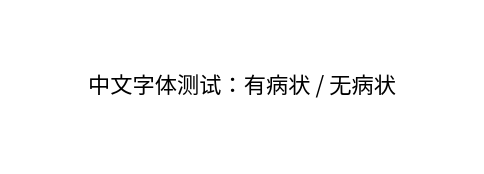

In [16]:
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

# 依次寻找服务器上可能存在的中文字体
font_candidates = [
    Path("/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc"),
    Path("/usr/share/fonts/opentype/noto/NotoSansCJKsc-Regular.otf"),
    Path("/usr/share/fonts/truetype/wqy/wqy-zenhei.ttc"),
    Path("/root/autodl-tmp/fonts/NotoSansCJKsc-Regular.otf"),
    Path("/root/autodl-tmp/fonts/SourceHanSansSC-Regular.otf"),
]

font_path = next(
    (path for path in font_candidates if path.is_file()),
    None
)

if font_path is None:
    raise FileNotFoundError(
        "服务器没有找到中文字体。请把中文字体文件上传到："
        "/root/autodl-tmp/fonts/"
    )

# 直接向当前 Matplotlib 注册字体，不依赖旧字体缓存
fm.fontManager.addfont(str(font_path))

# 使用字体文件内部的真实名称，避免手写名称不匹配
chinese_font_name = fm.FontProperties(
    fname=str(font_path)
).get_name()

plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = [
    chinese_font_name,
    "DejaVu Sans",
]
plt.rcParams["axes.unicode_minus"] = False

print("中文字体文件：", font_path)
print("字体内部名称：", chinese_font_name)

# 实际显示测试
fig, ax = plt.subplots(figsize=(6, 2))
ax.text(
    0.5,
    0.5,
    "中文字体测试：有病状 / 无病状",
    ha="center",
    va="center",
    fontsize=16,
)
ax.axis("off")
plt.show()

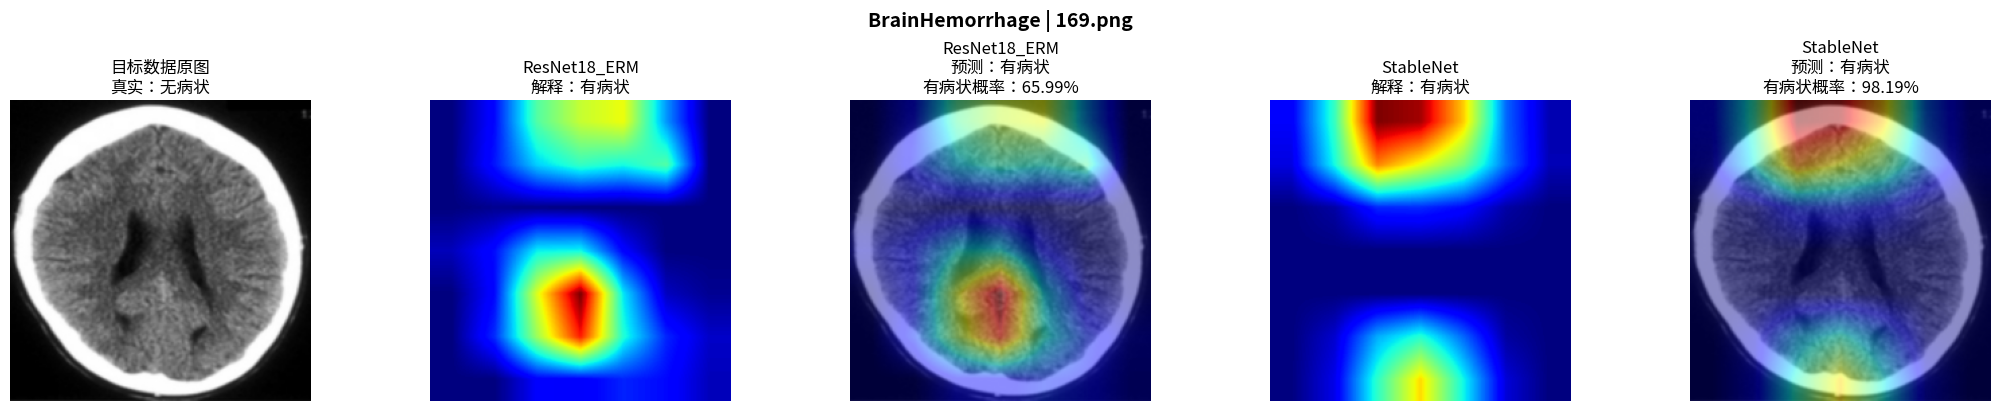

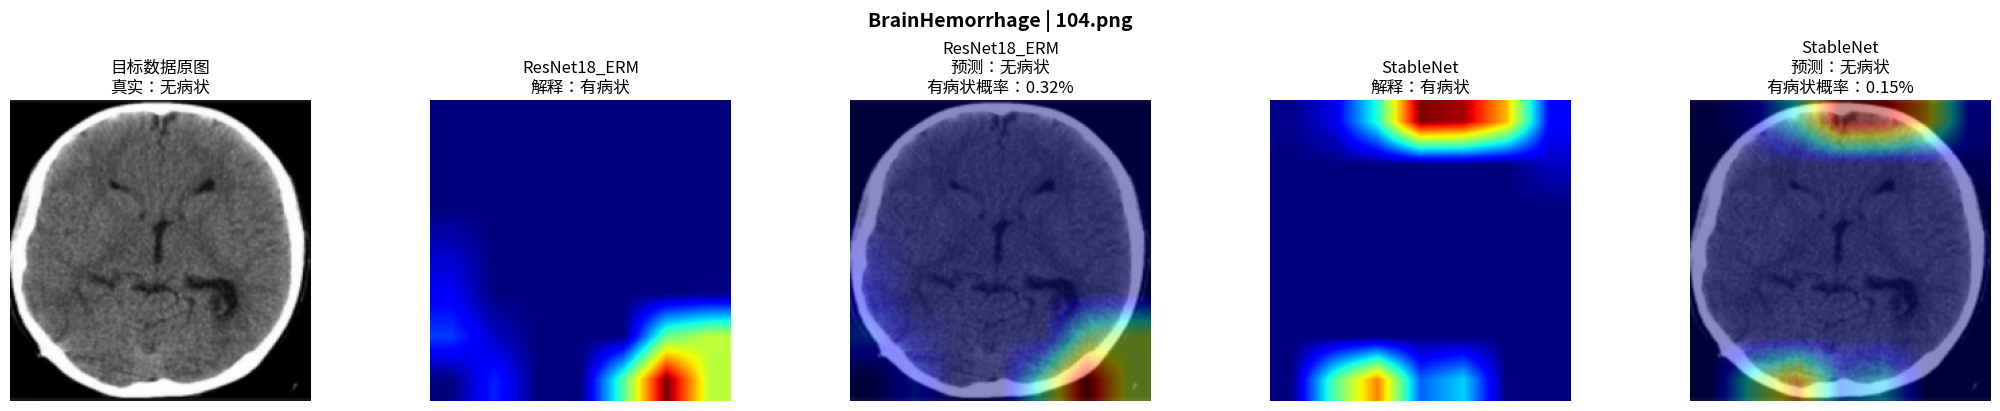

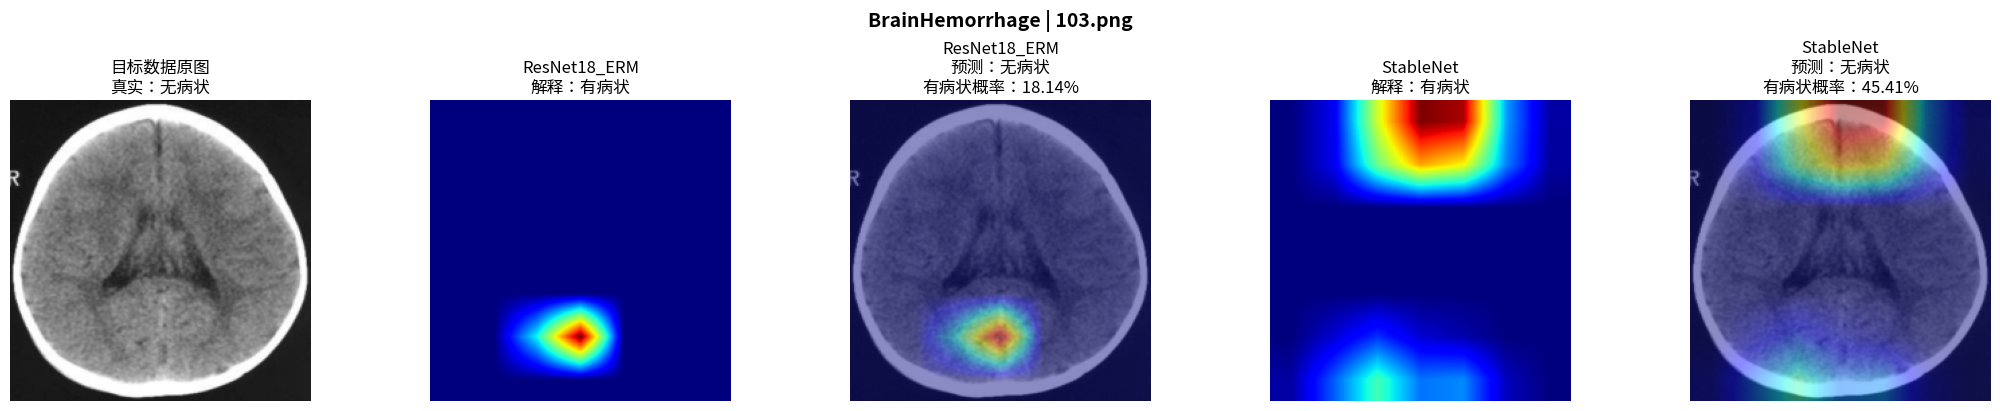

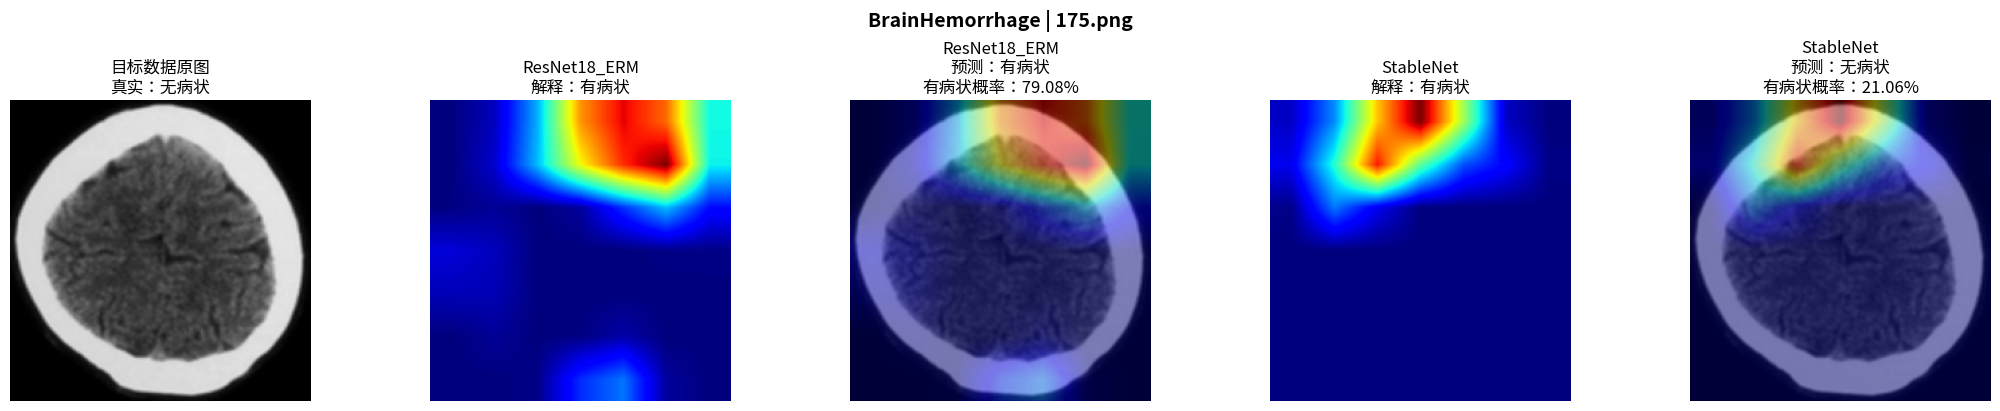

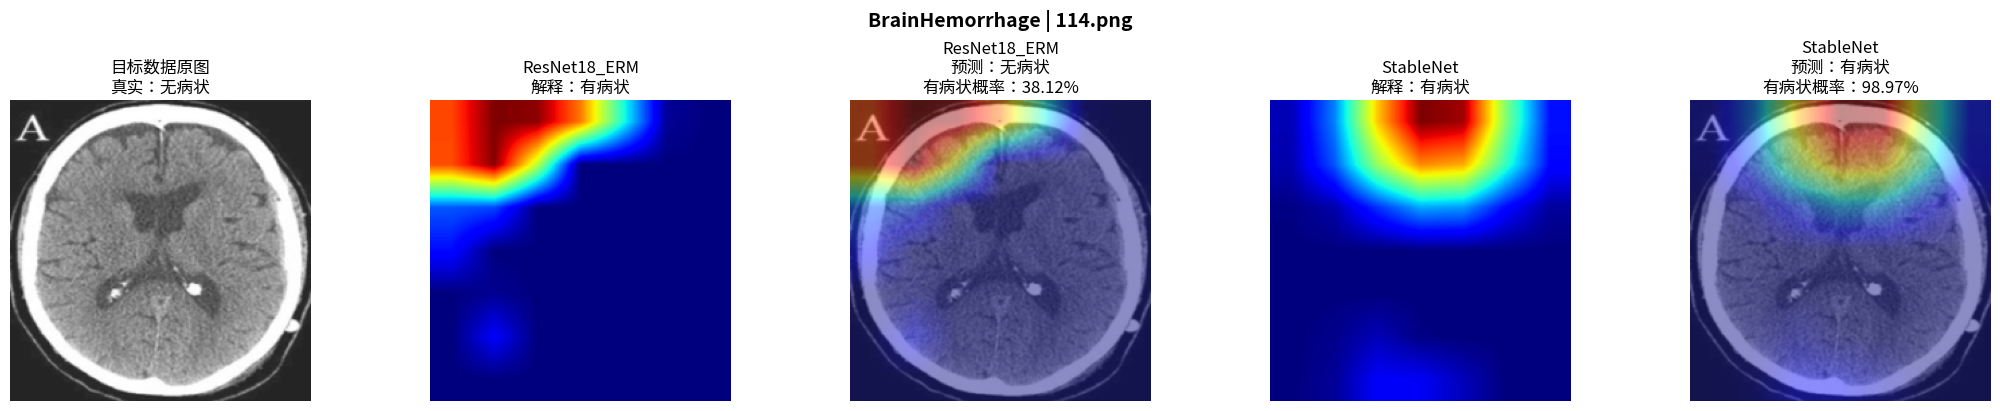

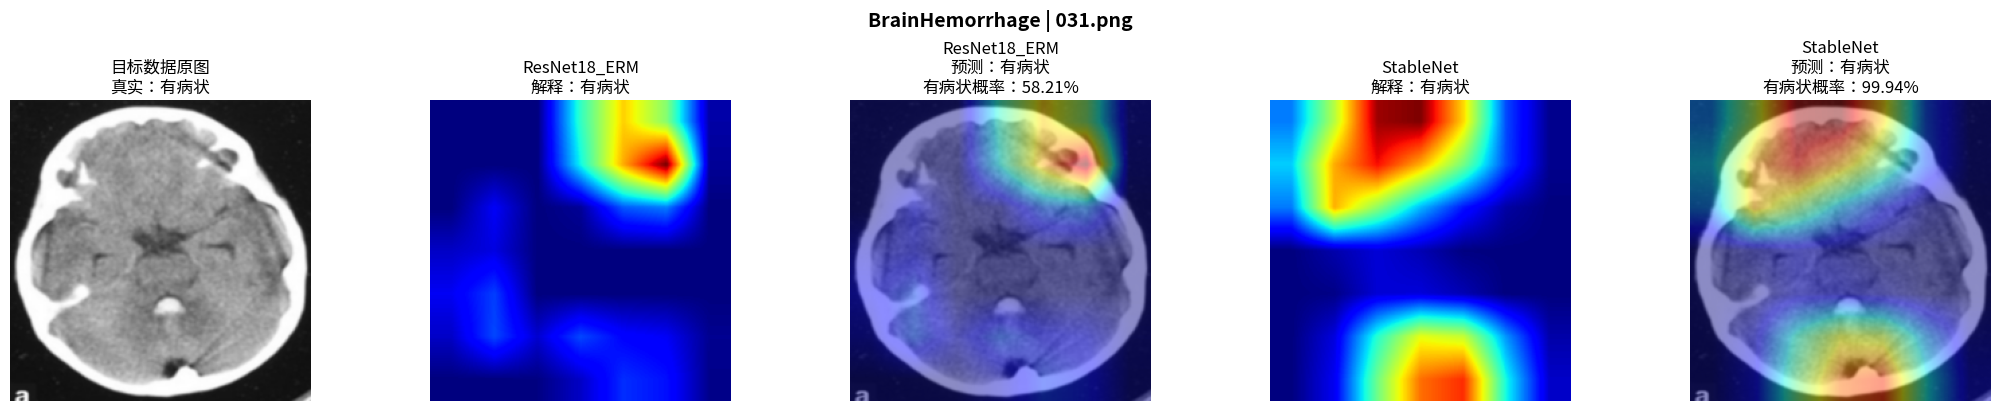

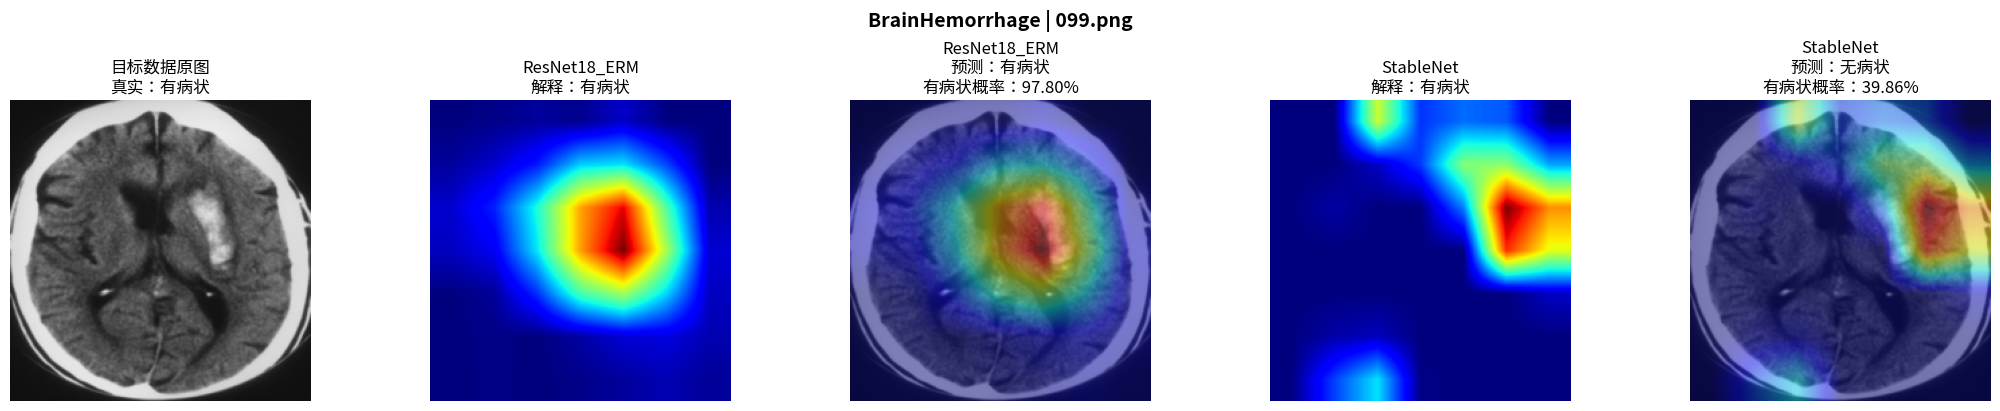

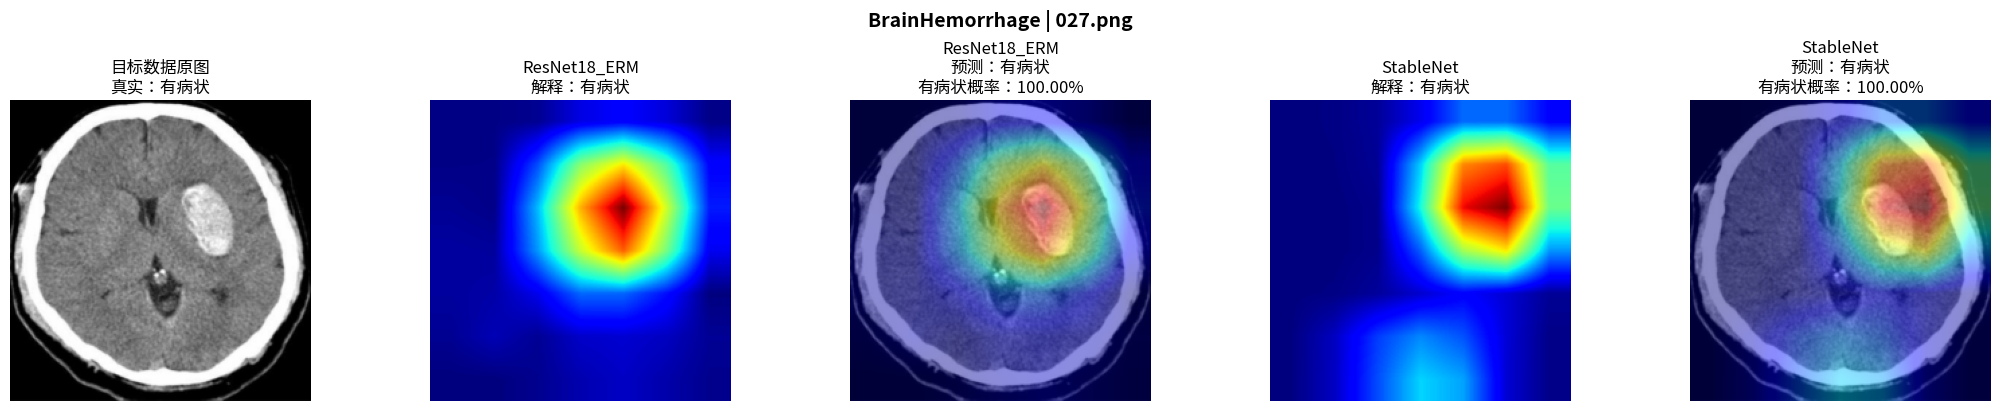

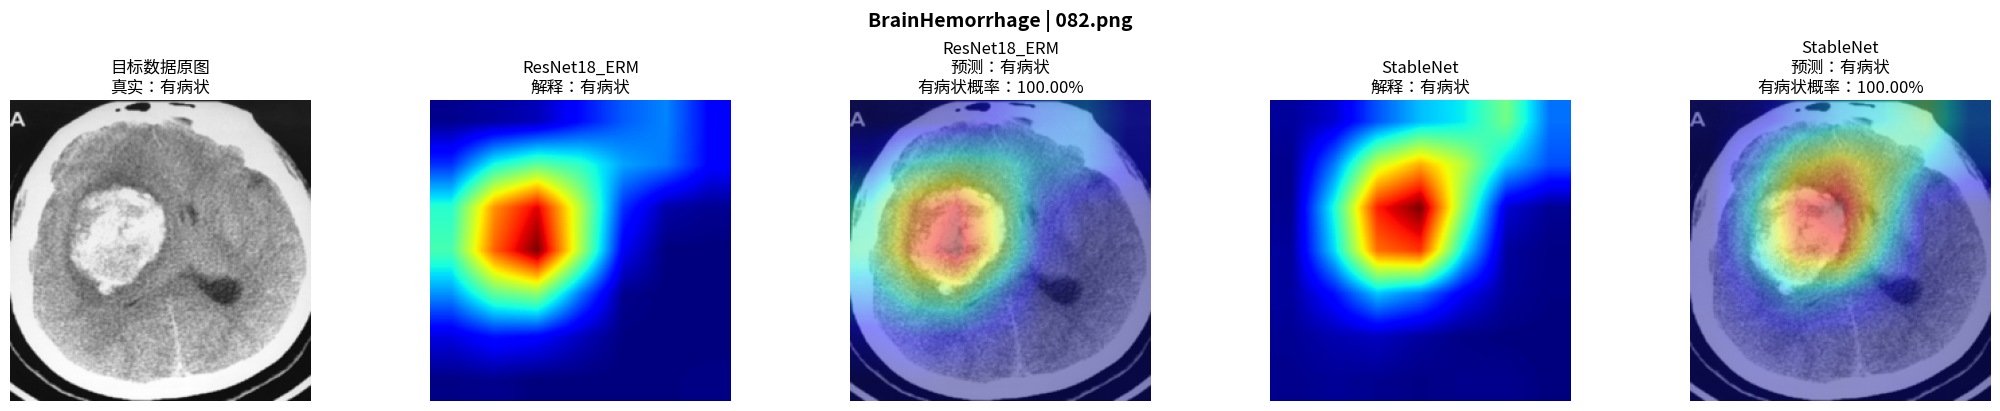

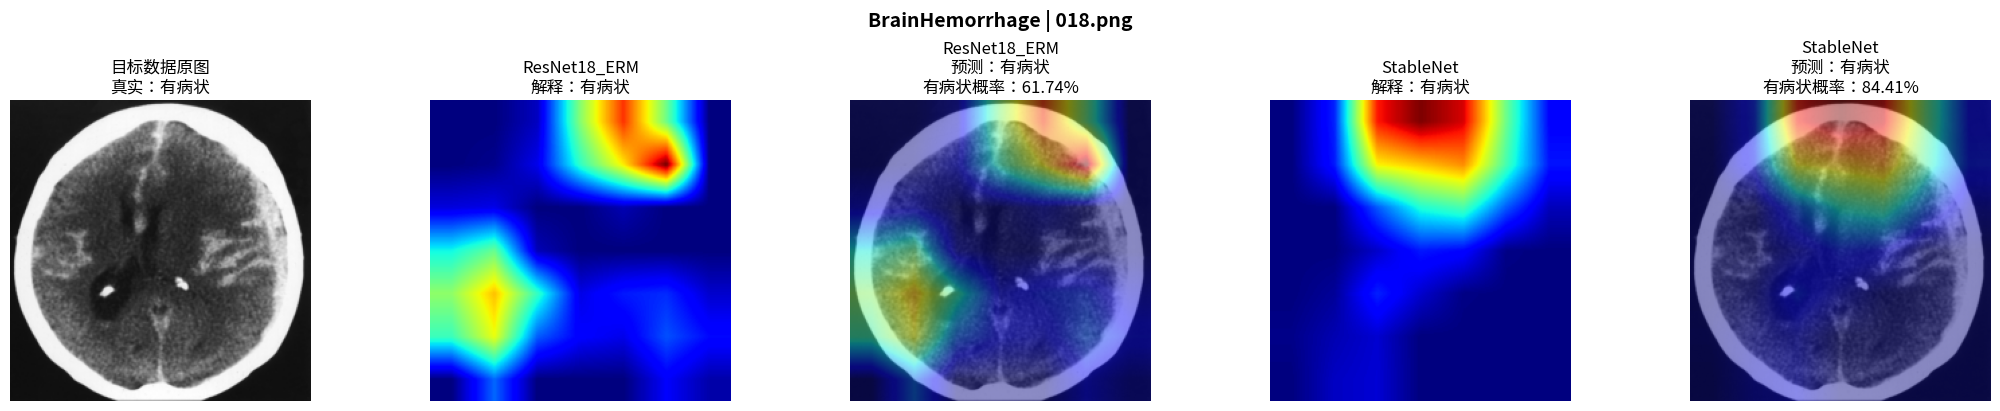

,target_image,true_label,method,predicted_label,prediction_confidence,disease_probability,correct
0,/root/autodl-tmp/medical_data/brain_hemorrhage...,无病状,ResNet18_ERM,有病状,65.994537,65.994537,False
1,/root/autodl-tmp/medical_data/brain_hemorrhage...,无病状,StableNet,有病状,98.186340,98.186340,False
2,/root/autodl-tmp/medical_data/brain_hemorrhage...,无病状,ResNet18_ERM,无病状,99.681061,0.318935,True
3,/root/autodl-tmp/medical_data/brain_hemorrhage...,无病状,StableNet,无病状,99.849251,0.150745,True
4,/root/autodl-tmp/medical_data/brain_hemorrhage...,无病状,ResNet18_ERM,无病状,81.860596,18.139408,True
5,/root/autodl-tmp/medical_data/brain_hemorrhage...,无病状,StableNet,无病状,54.589928,45.410069,True
6,/root/autodl-tmp/medical_data/brain_hemorrhage...,无病状,ResNet18_ERM,有病状,79.079269,79.079269,False
7,/root/autodl-tmp/medical_data/brain_hemorrhage...,无病状,StableNet,无病状,78.939453,21.060547,True
8,/root/autodl-tmp/medical_data/brain_hemorrhage...,无病状,ResNet18_ERM,无病状,61.879200,38.120796,True
9,/root/autodl-tmp/medical_data/brain_hemorrhage...,无病状,StableNet,有病状,98.967918,98.967918,False


Grad-CAM 数值记录输出： /root/autodl-tmp/train/results_cross_dataset_v1/tumor_to_hemorrhage_v1/cam_results.csv


In [17]:
cam_records = []
for image_path in cam_image_paths:
    true_index = EXPECTED_CLASSES[image_path.parent.name]
    figure, axes = plt.subplots(1, 5, figsize=(21, 4), constrained_layout=True)
    _, original_array = prepare_cam_image(image_path, cam_devices["ResNet18_ERM"])
    axes[0].imshow(original_array, cmap="gray")
    axes[0].set_title(f"目标数据原图\n真实：{HUMAN_LABELS[true_index]}")

    column = 1
    for method_name in ("ResNet18_ERM", "StableNet"):
        input_tensor, _ = prepare_cam_image(image_path, cam_devices[method_name])
        heatmap, predicted_class, explained_class, probabilities = cam_engines[method_name](
            input_tensor, target_class=CAM_TARGET_CLASS
        )
        confidence = float(probabilities[predicted_class] * 100)
        disease_probability = float(probabilities[1] * 100)
        color_heatmap = plt.get_cmap("jet")(heatmap)[..., :3]
        overlay = np.clip(0.55 * original_array + 0.45 * color_heatmap, 0, 1)

        axes[column].imshow(heatmap, cmap="jet", vmin=0, vmax=1)
        axes[column].set_title(f"{method_name}\n解释：{HUMAN_LABELS[explained_class]}")
        axes[column + 1].imshow(overlay)
        axes[column + 1].set_title(
            f"{method_name}\n预测：{HUMAN_LABELS[predicted_class]}\n"
            f"有病状概率：{disease_probability:.2f}%"
        )
        column += 2
        cam_records.append({
            "target_image": str(image_path),
            "true_label": HUMAN_LABELS[true_index],
            "method": method_name,
            "predicted_label": HUMAN_LABELS[predicted_class],
            "prediction_confidence": confidence,
            "disease_probability": disease_probability,
            "correct": predicted_class == true_index,
        })

    for axis in axes:
        axis.axis("off")
    figure.suptitle(f"{TARGET_NAME} | {image_path.name}", fontsize=14, fontweight="bold")
    plt.show()

for engine in cam_engines.values():
    engine.close()

cam_results_df = pd.DataFrame(cam_records)
cam_results_df.to_csv(RUN_ROOT / "cam_results.csv", index=False)
display(cam_results_df)
print("Grad-CAM 数值记录输出：", RUN_ROOT / "cam_results.csv")

## 结果解释注意事项

1. 如果跨数据集结果接近随机水平，并不代表训练失败，而可能说明两种疾病的影像特征、扫描模态或数据来源差异很大。
2. 如果结果异常高，要优先检查患者级数据泄漏、重复图片、文字/边框/设备标记和 CT/MRI 模态捷径。
3. 本实验只证明模型在两个现有数据集之间的迁移表现，不能直接推广为临床上的“通用病状检测器”。
4. 模型选择只依据源验证集。目标测试指标、Grad-CAM 和目标图片都不得反过来用于挑 seed、epoch 或超参数。
5. 最终科学报告应同时给出 5 个随机种子的均值±标准差、混淆矩阵，以及两个方向分别独立的结果。